# DSA8002 Coursework Question 2 [50 Marks]

--- 

In this assignment, you will analyze a fictional dataset of a city’s public bike rental program.

Complete the tasks below using this Jupyter notebook. For each task, you have been provided with code and markdown cells (if applicable) to enter your answers.

You may add additional code or markdown cells if required, e.g. for testing code.
    
Ensure that all code cells are **fully commented**. Code without detailed comments will lose marks.

You must import any required packages at the beginning of this notebook.

**Execute all cells before saving and submitting!**


---

In [69]:
# Import packages here
import pandas as pd
import matplotlib.pyplot as plt
import pandasql as ps
import numpy as np

---

## Task 1: Load and Explore the Data  

You are given a CSV file bike_rentals.csv with the following columns:

- `rental_id`: Unique ID for each rental
- `user_type`: "Member" or "Casual"
- `start_time`: Rental start time (YYYY-MM-DD HH:MM)
- `end_time`: Rental end time
- `start_station`: Station name where rental started
- `end_station`: Station name where rental ended
- `duration_minutes`: Duration of rental in minutes
- `bike_id`: Unique ID of the bike

Write a function called load_data() that:

- Loads the data into a Pandas DataFrame

- Parses the start_time and end_time as datetime objects

- Prints:
  - Number of rows
  - Column names and types
  - First 5 rows

**Hint**: look at the datetime arguments available within `pandas.read_csv()` -- https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

Load the data and display the first five rows.

### Function:

In [70]:
# Function that loads the bike rental data from it's CSV file, parses dates and prints overview of the dataset
def load_data():

    # Reads the bike rentals CSV file and parses the start_time and end_time as datetime objects
    bike_rentals_df = pd.read_csv('bike_rentals.csv', parse_dates=['start_time', 'end_time'])

    # Prints the number of rows in the bike rentals DataFrame 
    print(f"Number of rows: {len(bike_rentals_df)}")

    # Prints the column names and the corresponding data type of each column
    print(f"Column names and data types:\n\n{bike_rentals_df.dtypes}")

    # Prints the first five rows of the DataFrame
    display(bike_rentals_df.head())

    return bike_rentals_df

### Create the dataframe and print the information using your function:

In [71]:
# Calls the load_data function
bike_rentals_df = load_data()

Number of rows: 1103
Column names and data types:

rental_id                   object
user_type                   object
start_time          datetime64[ns]
end_time            datetime64[ns]
start_station               object
end_station                 object
duration_minutes           float64
bike_id                     object
dtype: object


,rental_id,user_type,start_time,end_time,start_station,end_station,duration_minutes,bike_id
0,R00001,Member,2023-01-01 06:31:00,2023-01-01 06:39:00,Times Square,Times Square,8.0,B088
1,R00002,Member,2023-01-01 07:21:00,2023-01-01 07:22:00,Brooklyn Bridge,Times Square,1.0,B014
2,R00003,Casual,2023-01-01 14:36:00,2023-01-01 15:37:00,Brooklyn Bridge,Wall Street,1.0,B073
3,R00004,Member,2023-01-01 22:25:00,2023-01-01 22:28:00,Wall Street,Times Square,3.0,B018
4,R00005,Casual,2023-01-02 02:06:00,2023-01-02 02:29:00,Times Square,Union Square,23.0,B039


---

## Task 2: Clean and Process the Data

Create a function clean_data(df) that processes the data by doing the following operations:

- Drops rows where duration_minutes is missing or less than 1

- Removes duplicate rental_ids

- Fills any missing values in user_type with "Unknown"

- Creates a new column rental_day containing only the date (not time) from start_time

- Creates a new column rental_hour for the hour of day the rental started

- Prints the number of rows

- Returns the cleaned DataFrame.


### Function:

In [72]:
# Function that cleans the bike rentals DataFrame by removing duplicates, filling missing values, and creating new columns
def clean_data(df):
    
    # Drops rows with missing durations or durations less than 1 minute long
    df = df[df['duration_minutes'] >= 1]
    
    # Removes duplicate rental ids
    df = df.drop_duplicates(subset=['rental_id'])

    # Fills missing user types with 'Unknown'
    df['user_type'] = df['user_type'].fillna('Unknown')

    # Extracts date from start_time and makes new column in DataFrame called rental_day
    df['rental_day'] = df['start_time'].dt.date

    # Extracts hour of rental from start_time and makes new column in DataFrame called rental_hour
    df['rental_hour'] = df['start_time'].dt.hour

    # Prints number of rows in cleaned DataFrame
    print(f"Number of rows after cleaning DataFrame: {len(df)}")

    return df

### Execute this function and **display the first five rows**:

In [73]:
# Calls the clean_data function to clean the bike rental DataFrame
cleaned_bike_rentals_df = clean_data(bike_rentals_df)

# Displays the first five rows of the cleaned bike rentals DataFrame
cleaned_bike_rentals_df.head()

Number of rows after cleaning DataFrame: 1098


,rental_id,user_type,start_time,end_time,start_station,end_station,duration_minutes,bike_id,rental_day,rental_hour
0,R00001,Member,2023-01-01 06:31:00,2023-01-01 06:39:00,Times Square,Times Square,8.0,B088,2023-01-01,6
1,R00002,Member,2023-01-01 07:21:00,2023-01-01 07:22:00,Brooklyn Bridge,Times Square,1.0,B014,2023-01-01,7
2,R00003,Casual,2023-01-01 14:36:00,2023-01-01 15:37:00,Brooklyn Bridge,Wall Street,1.0,B073,2023-01-01,14
3,R00004,Member,2023-01-01 22:25:00,2023-01-01 22:28:00,Wall Street,Times Square,3.0,B018,2023-01-01,22
4,R00005,Casual,2023-01-02 02:06:00,2023-01-02 02:29:00,Times Square,Union Square,23.0,B039,2023-01-02,2


---

## Task 3: Analyze with Pandas

Write a function `analyze_data()` that returns the following information in a dictionary:

- The hour of the day with the highest number of rentals

- The most popular start station

- The day of the week on which rentals are most frequent (you may need to consult the Pandas datetime documentation)

Your function must also:

- Plot a bar chart showing the average rental durations for each user type

- **Optional extra**: mark the standard deviation of rental durations for each user type on the plot


### Function:

In [74]:
# Function that analyses the bike rental data, generates a bar chart and returns results in a dictionary
def analyze_data(df):

    # Results dictionary
    results = {}

    # Groups the data by rental hour, counts the number rentals for each hour, gets the rental hour with the most rentals and stores in a dictionary
    results['peak_hour'] = df['rental_hour'].mode()[0]

    # Finds the station with the most number of rentals started at it and stores in a dictionary
    results['most_popular_station'] = df['start_station'].mode()[0]

    # Converts rental_day to datetime format, finds the day where the most number of rentals occur and stores in a dictionary
    results['most_frequent_day'] = pd.to_datetime(df['rental_day']).dt.day_name().mode()[0]

    # Gets user types
    user_types = df['user_type'].unique()
    
    # Calculates average rental duration for each user type
    user_type_avg_durations = df.groupby('user_type')['duration_minutes'].mean()

    # Calculates standard deviation of rental duration for each user type
    user_type_std_durations = df.groupby('user_type')['duration_minutes'].std()

    # Creates the plot
    fig, ax = plt.subplots()

    # Plots a bar chart of average rental duration by user type with error bars showing standard deviation
    ax.bar(user_type_avg_durations.index, user_type_avg_durations.values, yerr= user_type_std_durations.values, capsize=10)

    # Sets x and y labels
    ax.set_xlabel('User Type')
    ax.set_ylabel('Average Duration (minutes)')

    # Sets the title
    ax.set_title('Average Rental Duration by User Type')

    # Displays grid
    ax.grid()

    # Saves the plot as a png
    plt.savefig('average_rental_duration_by_user_type.png')

    # Displays the plot
    plt.show()

    return results


### Create the plot using your function:

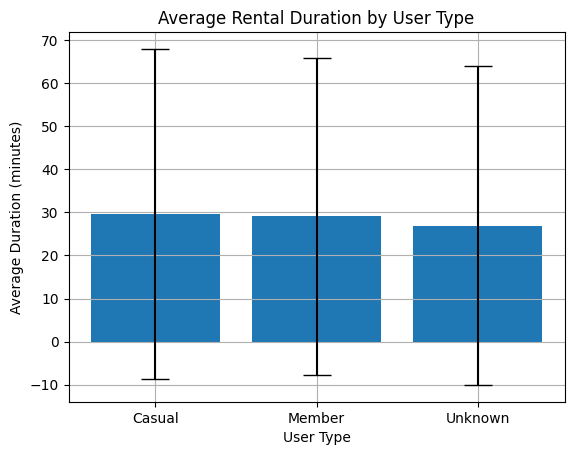

In [75]:
# Calls the analyze data function analyse the bike rental data
analysis_results = analyze_data(cleaned_bike_rentals_df)

### Print Statements for Analysis

In [76]:
# Prints the analysis results
print(f"Peak hour: {analysis_results['peak_hour']}")
print(f"Most popular start station: {analysis_results['most_popular_station']}")
print(f"Most frequent day for rentals: {analysis_results['most_frequent_day']}")

Peak hour: 21
Most popular start station: Central Park
Most frequent day for rentals: Tuesday


### Comment on your plot: are the differences between user times significant? Justify your answer

In [77]:
avg_rental_by_user_type = cleaned_bike_rentals_df.groupby(['user_type'])['duration_minutes'].mean().reset_index(name='avg_duration_minutes')

avg_rental_by_user_type

,user_type,avg_duration_minutes
0,Casual,29.559099
1,Member,29.031189
2,Unknown,26.903846


The differences between the average rental duration for each user type doesn't appear to be significant. The mean durations for Members, Casual users and Unknown users are all close in value. Ranging from $26.90$ mins (to $2$ d.p) for Unknown users to $29.56$ mins (to $2$ d.p) for Casual users with Members having an average duration of $29.03$ mins (to $2$ d.p). The large standard deviation bars overlap substantially, indicating that the variation within each group is much larger than the difference between their between their averages. This suggest there is no clear distinction in rental duration based on user type.

---

## Task 4: Query with SQL 

## (a)
Write a function `run_sql_queries()` that runs the following queries on the dataframe and prints the results:

- Select the total number of rentals

- Find the average rental duration for "Casual" users

- Count how many rentals started and ended at the same station

- List all distinct bike IDs used in April

**Hint**: You may need to use the SQL strftime funtion -- https://www.w3resource.com/sqlite/sqlite-strftime.php

### Function:

In [78]:
# Function that runs SQL queries on the bike rental DataFrame and prints the results
def run_sql_queries(df):

    # SQL query to count total number of  bike rentals
    query1 = "SELECT COUNT(*) AS [total_rentals] FROM df" 

    # SQL query to calculate average bike rental duration for casual users
    query2 = "SELECT AVG(duration_minutes) AS [average_duration] FROM df WHERE user_type = 'Casual'"

    # SQL query to count the number of rentals starting and ending at the same station
    query3 = "SELECT COUNT(*) AS [same_station_rentals] FROM df WHERE start_station = end_station"

    # SQL query to list distinct bike IDs used in April
    query4 = "SELECT DISTINCT bike_id FROM df WHERE strftime('%m', start_time) = '04'"

    # Executes the SQL queries and prints the results
    print(f"Total rentals: {ps.sqldf(query1, locals()).values}")
    print(f"Average rental duration for casual users: {ps.sqldf(query2).values}")
    print(f"Number of rentals starting and ending at the same station: {ps.sqldf(query3).values}")
    print(f"Distinct Bike IDs used in April: {ps.sqldf(query4).values}")


### Execute your function:

In [79]:
# Calls the run_sql_queries function with the cleaned bike rentals DataFrame
run_sql_queries(cleaned_bike_rentals_df)

Total rentals: [[1098]]
Average rental duration for casual users: [[29.55909944]]
Number of rentals starting and ending at the same station: [[296]]
Distinct Bike IDs used in April: [['B098']
 ['B043']
 ['B059']
 ['B042']
 ['B026']
 ['B009']
 ['B024']
 ['B083']
 ['B016']
 ['B019']
 ['B092']
 ['B094']
 ['B005']
 ['B047']
 ['B008']
 ['B007']
 ['B020']
 ['B001']
 ['B031']
 ['B040']
 ['B076']
 ['B032']
 ['B036']
 ['B003']
 ['B027']
 ['B095']
 ['B002']
 ['B055']
 ['B070']
 ['B010']
 ['B049']
 ['B039']
 ['B072']
 ['B088']
 ['B063']
 ['B030']
 ['B066']
 ['B048']
 ['B054']
 ['B057']
 ['B096']
 ['B056']
 ['B086']
 ['B053']
 ['B087']
 ['B015']
 ['B058']
 ['B035']
 ['B044']
 ['B037']
 ['B017']
 ['B073']
 ['B069']
 ['B038']
 ['B093']
 ['B089']
 ['B078']
 ['B068']
 ['B097']
 ['B013']
 ['B012']
 ['B060']
 ['B075']
 ['B052']
 ['B100']
 ['B034']
 ['B091']
 ['B025']
 ['B014']
 ['B033']
 ['B067']
 ['B006']
 ['B079']
 ['B045']
 ['B021']
 ['B004']
 ['B077']
 ['B061']
 ['B090']]


---

## (b)

The file bike_info.csv contains more information about the bikes that are available to rent. It contains the following columns:

- `bike_id`: this is the same ID code used in the rentals database
- `colour`
- `year`

Write and execute an SQL query to determine the most common colour of bike collected by **Members** from the station **Brooklyn Bridge**.

### Read the file bike_info.csv and display the first 5 rows:

In [80]:
# Reads the bike info CSV file
bike_info = pd.read_csv('bike_info.csv')

# Displays the first 5 rows of the bike info DataFrame
bike_info.head()

,bike_id,colour,year
0,B083,black,2020
1,B002,blue,2019
2,B076,black,2021
3,B060,blue,2019
4,B051,red,2020


### Your query:

In [81]:
# SQL query to find the most common bike colour rented by members at Brooklyn Bridge station
query5 = """
SELECT b.colour, COUNT(colour) AS [colour_count] FROM cleaned_bike_rentals_df r
JOIN bike_info b on r.bike_id = b.bike_id
WHERE r.user_type = 'Member' AND r.start_station = 'Brooklyn Bridge'
GROUP BY b.colour
ORDER BY colour_count DESC
LIMIT 1
"""

# Executes the SQL query and stores the result
most_common_colour = ps.sqldf(query5).values

# Prints the result of the SQL query
print(f"Most common bike colour rented by members at Brooklyn Bridge Station is {most_common_colour[0][0]} with a rental count of {most_common_colour[0][1]}")

Most common bike colour rented by members at Brooklyn Bridge Station is black with a rental count of 33


---

## (c)

Write an SQL query that finds the average rental duration for each bike ID, returning **only** those bikes where the average rental time is less than 20 minutes.

### Your query:

In [82]:
# SQL query to find the average rental duration for each bike ID, excluding rentals with an average duration longer than 20 minutes
query6 = """
SELECT bike_id, AVG(duration_minutes) AS [avg_duration] FROM cleaned_bike_rentals_df
GROUP BY bike_id
HAVING AVG(duration_minutes) < 20
"""

# Executes the SQL query and stores the result
avg_durations = ps.sqldf(query6)

# Prints the result of the SQL query
print("Average rental duration for each Bike ID with average rental duration less than 20 minutes:")

# Displays results
avg_durations

Average rental duration for each Bike ID with average rental duration less than 20 minutes:


,bike_id,avg_duration
0,B009,15.000000
1,B012,16.111111
2,B015,19.428571
3,B018,11.272727
4,B024,12.875000
5,B028,15.875000
6,B044,13.142857
7,B045,13.454545
8,B046,19.000000
9,B047,17.333333


---

## Task 5: Understanding outliers

## (a)

Write code in Python or SQL to create a dataframe that contains any bike rentals with an unusually long duration. 

It is up to you to decide how to define an unusually long duration.

You may find it helpful to use an appropriate plot in justifying your decision.

### Your code:

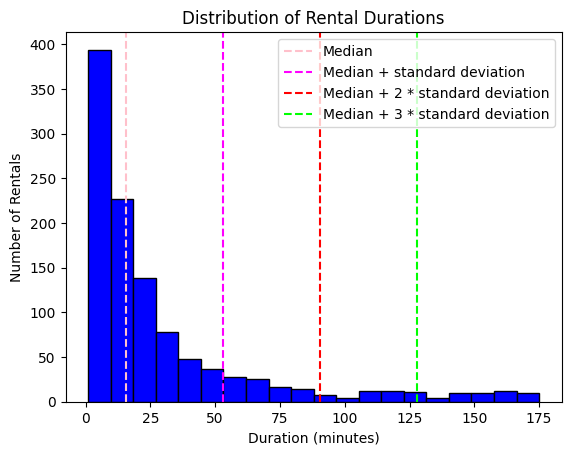

Long Rental Duration Threshold: 90.51 minutes
The threshold is 90.51 mins
Number of Long Rentals: 90


In [83]:
# Calculates median for rental duration
median_duration = cleaned_bike_rentals_df['duration_minutes'].median()

# Calculates standard deviation for rental duration
std_duration = cleaned_bike_rentals_df['duration_minutes'].std()

# Creates the plot
fig, ax = plt.subplots()

# Plots a histogram of all rental durations
ax.hist(cleaned_bike_rentals_df['duration_minutes'], color='blue', bins=20, edgecolor='black')

# Plots a pink coloured vertical dashed line at median
ax.axvline(median_duration, color='pink', linestyle='dashed', label='Median')

# Plots a magenta coloured vertical dashed line at median + standard deviation
ax.axvline(median_duration + std_duration, color='magenta', linestyle='dashed', label='Median + standard deviation')

# Plots a red coloured vertical dashed line at median + 2 * standard deviation
ax.axvline(median_duration + 2 * std_duration, color='red', linestyle='dashed', label='Median + 2 * standard deviation')

# Plots a lime coloured vertical dashed line at median + 3 * standard deviation
ax.axvline(median_duration + 3 * std_duration, color='lime', linestyle='dashed', label='Median + 3 * standard deviation')

# Sets x and y labels
ax.set_xlabel('Duration (minutes)')
ax.set_ylabel('Number of Rentals')

# Sets title
ax.set_title('Distribution of Rental Durations')

# Displays legend and locks it to the top right
ax.legend(loc='upper right')

# Saves the plot as a png
plt.savefig('rental_duration_distribution.png')

# Displays the plot
plt.show()

# Calculates a threshold for classifying a rental as long
threshold = median_duration + 2 * std_duration

# Prints the threshold duration
print(f"Long Rental Duration Threshold: {threshold:.2f} minutes")

# Filters the DataFrame to only include rentals longer than the threshold
long_rentals = cleaned_bike_rentals_df[cleaned_bike_rentals_df['duration_minutes'] > threshold]

# Prints threshold
print(f'The threshold is {threshold:.2f} mins')

# Prints the number of long rentals
print(f"Number of Long Rentals: {len(long_rentals)}")

### Explain how you decided on your definition of an unusually long rental:

I defined an unusually long rental as any trip with a duration greater than the median plus twice the standard deviation of all rentals durations. The median was used instead of the mean as it is less affected by extreme values, while the standard deviation provides a measure of spread in data. To make my choice, I plotted vertical lines for the median, median $+$ std, median $+ 2 \times$ std and median $+ 3 \times$ std. The plot showed that most rentals fall below the median $+ 2 \times$ std threshold, with only a small number of rentals extending beyond it. This confirms that a journey longer than $90.51$ mins can be reasonably considered an unusually long rental.

## (b)

Use your dataframe from part **(a)**, and write Python or SQL code to investigate which factors (i.e. columns) in the dataset are most associated with unusually long rental durations.

Create an appropriate plot that illustrates your findings.


### Your code to analyse the data:

In [84]:
# Calculates the number of long rentals by user type
user_long_counts = long_rentals['user_type'].value_counts().reset_index(name='Long_Count')

# Calculates the total number of rentals by user type
user_total_counts = cleaned_bike_rentals_df['user_type'].value_counts().reset_index(name='Total_Count')

# Merges both counts to compare long rentals to total rentals by user type
user_long_summary = pd.merge(user_long_counts, user_total_counts, on='user_type', how='left')

# Calculates the percentage of long rentals for each user type
user_long_summary['Percent_Long'] = (user_long_summary['Long_Count'] / user_long_summary['Total_Count']) * 100

# Adds a total row at the bottom
user_long_summary.loc['Total'] = ['', user_long_summary['Long_Count'].sum(), user_long_summary['Total_Count'].sum(), user_long_summary['Long_Count'].sum() / user_long_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("User types with long rentals compared to all journeys:")
display(user_long_summary)

# Calculates the number of long rentals by start station
start_long_counts = long_rentals['start_station'].value_counts().reset_index(name='Long_Count')

# Calculates the total number of rentals by start station
start_total_counts = cleaned_bike_rentals_df['start_station'].value_counts().reset_index(name='Total_Count')

# Merges both counts to compare long rentals to total rentals by start station
start_long_summary = pd.merge(start_long_counts, start_total_counts, on='start_station', how='left')

# Calculates the percentage of long rentals for each start station
start_long_summary['Percent_Long'] = (start_long_summary['Long_Count'] / start_long_summary['Total_Count']) * 100

# Adds a total row at the bottom
start_long_summary.loc['Total'] = ['', start_long_summary['Long_Count'].sum(), start_long_summary['Total_Count'].sum(), start_long_summary['Long_Count'].sum() / start_long_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("Start stations with long rentals compared to all journeys:")
display(start_long_summary)

# Calculates the number of long rentals by end station
end_long_counts = long_rentals['end_station'].value_counts().reset_index(name='Long_Count')

# Calculates the total number of rentals by end station
end_total_counts = cleaned_bike_rentals_df['end_station'].value_counts().reset_index(name='Total_Count')

# Merges both counts to compare long rentals to total rentals by end station
end_long_summary = pd.merge(end_long_counts, end_total_counts, on='end_station', how='left')

# Calculates the percentage of long rentals for each start station
end_long_summary['Percent_Long'] = (end_long_summary['Long_Count'] / end_long_summary['Total_Count']) * 100

# Adds a total row at the bottom
end_long_summary.loc['Total'] = ['', end_long_summary['Long_Count'].sum(), end_long_summary['Total_Count'].sum(), end_long_summary['Long_Count'].sum() / end_long_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("End stations with long rentals compared to all journeys:")
display(end_long_summary)

# Calculates the number of long rentals that start and end at the same station
same_station_long_counts = (long_rentals[long_rentals['start_station'] == long_rentals['end_station']]['start_station'].value_counts().reset_index(name='Long_Count'))

# Calculates the total number of rentals that start and end at the same station
same_station_total_counts = (cleaned_bike_rentals_df[cleaned_bike_rentals_df['start_station'] == cleaned_bike_rentals_df['end_station']]['start_station'].value_counts().reset_index(name='Total_Count'))

# Merges both counts to compare long rentals to total rentals by start station
same_station_summary = pd.merge(same_station_long_counts, same_station_total_counts, on='start_station', how='left')

# Calculates the percentage of long rentals for each station
same_station_summary['Percent_Long'] = (same_station_summary['Long_Count'] / same_station_summary['Total_Count'] * 100)

# Adds a total row at the bottom
same_station_summary.loc['Total'] = ['', same_station_summary['Long_Count'].sum(), same_station_summary['Total_Count'].sum(), same_station_summary['Long_Count'].sum() / same_station_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("Stations with long rentals that start and end at the same station compared to all same station journeys:")
display(same_station_summary)

# Calculates the number of long rentals by Bike ID
bike_long_counts = long_rentals['bike_id'].value_counts().reset_index(name='Long_Count')

# Calculates the total number of rentals by Bike ID
bike_total_counts = cleaned_bike_rentals_df['bike_id'].value_counts().reset_index(name='Total_Count')

# Merges both counts to compare long rentals to total rentals by Bike ID
bike_long_summary = pd.merge(bike_long_counts, bike_total_counts, on='bike_id', how='left')

# Calculates the percentage of long rentals for each Bike ID
bike_long_summary['Percent_Long'] = (bike_long_summary['Long_Count'] / bike_long_summary['Total_Count']) * 100

# Adds a total row at the bottom
bike_long_summary.loc['Total'] = ['', bike_long_summary['Long_Count'].sum(), bike_long_summary['Total_Count'].sum(), bike_long_summary['Long_Count'].sum() / bike_long_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("Bike IDs with long rentals compared to all journeys:")
display(bike_long_summary)

# Calculates the number of long rentals by hour of the day
hour_long_counts = long_rentals['rental_hour'].value_counts().reset_index(name='Long_Count')

# Calculates the total number of rentals by hour of the day
hour_total_counts = cleaned_bike_rentals_df['rental_hour'].value_counts().reset_index(name='Total_Count')

# Merges both counts to compare long rentals to total rentals by hour of the day
hour_long_summary = pd.merge(hour_long_counts, hour_total_counts, on='rental_hour', how='left')

# Calculates the percentage of long rentals for each hour of the day
hour_long_summary['Percent_Long'] = (hour_long_summary['Long_Count'] / hour_long_summary['Total_Count']) * 100

# Adds a total row at the bottom
hour_long_summary.loc['Total'] = ['', hour_long_summary['Long_Count'].sum(), hour_long_summary['Total_Count'].sum(), hour_long_summary['Long_Count'].sum() / hour_long_summary['Total_Count'].sum() * 100]

# Displays the summary table
print("Rental hours with long rentals compared to all journeys:")
display(hour_long_summary)

User types with long rentals compared to all journeys:


,user_type,Long_Count,Total_Count,Percent_Long
0,Casual,45,533,8.442777
1,Member,41,513,7.992203
2,Unknown,4,52,7.692308
Total,,90,1098,8.196721


Start stations with long rentals compared to all journeys:


,start_station,Long_Count,Total_Count,Percent_Long
0,Central Park,78,303,25.742574
1,Times Square,7,195,3.589744
2,Wall Street,3,220,1.363636
3,Union Square,1,199,0.502513
4,Brooklyn Bridge,1,181,0.552486
Total,,90,1098,8.196721


End stations with long rentals compared to all journeys:


,end_station,Long_Count,Total_Count,Percent_Long
0,Central Park,79,308,25.649351
1,Brooklyn Bridge,6,198,3.030303
2,Union Square,3,195,1.538462
3,Times Square,2,200,1.000000
Total,,90,901,9.988901


... (2 outputs left out)

Bike IDs with long rentals compared to all journeys:


,bike_id,Long_Count,Total_Count,Percent_Long
0,B017,4,16,25.000000
1,B056,4,11,36.363636
2,B067,3,10,30.000000
3,B025,3,8,37.500000
4,B092,3,15,20.000000
...,...,...,...,...
57,B011,1,10,10.000000
58,B054,1,16,6.250000
59,B068,1,9,11.111111
60,B049,1,18,5.555556


Rental hours with long rentals compared to all journeys:


,rental_hour,Long_Count,Total_Count,Percent_Long
0,22,7,49,14.285714
1,15,7,45,15.555556
2,19,6,47,12.765957
3,11,6,50,12.000000
4,9,5,45,11.111111
5,7,5,51,9.803922
6,21,5,59,8.474576
7,16,4,44,9.090909
8,3,4,40,10.000000
9,0,4,42,9.523810


### Your code to produce an informative plot:

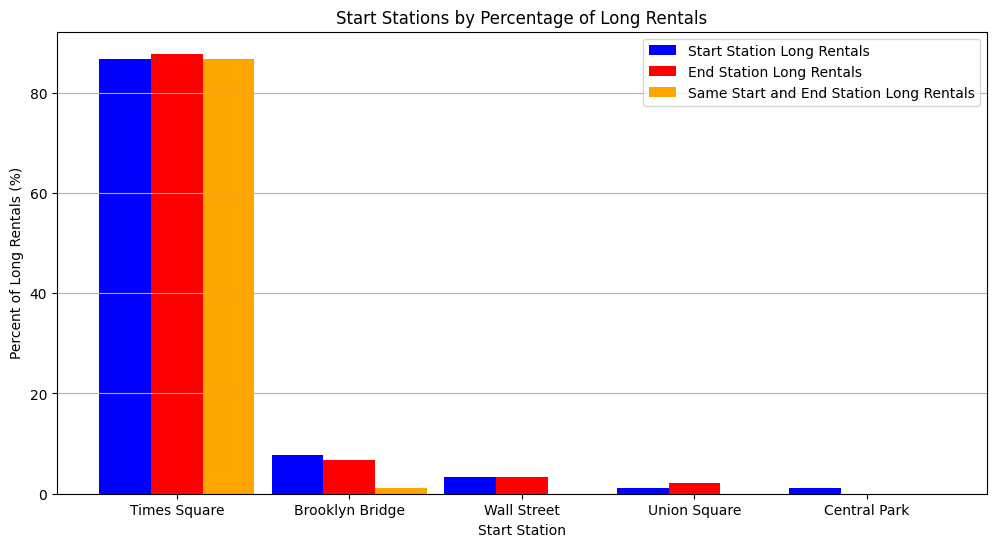

In [85]:
# Sets bar width
bar_width = 0.3

# Gets all unique station names 
all_stations = cleaned_bike_rentals_df[['start_station']].drop_duplicates()

# Makes copies of the respective summary DataFrame without the Total row
start_plot = start_long_summary.iloc[:-1].copy()
end_plot = end_long_summary.iloc[:-1].copy()
same_station_plot = same_station_summary.iloc[:-1].copy()

# Renames end_station column to start_station to make merging easier by station name
end_plot = end_plot.rename(columns={'end_station': 'start_station'})

# Merges all summary tables with the complete list of stations and fills missing stations with 0 for Long_Count
start_plot = all_stations.merge(start_plot[['start_station', 'Long_Count']], on='start_station', how='left').fillna(0)
end_plot = all_stations.merge(end_plot[['start_station', 'Long_Count']], on='start_station', how='left').fillna(0)
same_station_plot = all_stations.merge(same_station_plot[['start_station', 'Long_Count']], on='start_station', how='left').fillna(0)

# Sorts stations by Long_Count in descendig order
start_plot = start_plot.sort_values('Long_Count', ascending=False)
end_plot = end_plot.sort_values('Long_Count', ascending=False)
same_station_plot = same_station_plot.sort_values('Long_Count', ascending=False)

# Creates an array of x positions for each station
x = np.arange(len(all_stations))

# Creates the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Plots a bar chart showing the percentage of all long rentals started at each station in blue
ax.bar(x - bar_width, start_plot['Long_Count'] / start_plot['Long_Count'].sum() * 100, width=bar_width, color='blue', label='Start Station Long Rentals')

# Plots a bar chart showing the percentage of all long rentals ended at each station in red
ax.bar(x, end_plot['Long_Count'] / end_plot['Long_Count'].sum() * 100, width=bar_width, color='red', label='End Station Long Rentals')

# Plots a bar chart showing the percentage of all long rentals started and ended at the same station in orange
ax.bar(x + bar_width, same_station_plot['Long_Count'] / start_plot['Long_Count'].sum() * 100, width=bar_width, color='orange', label='Same Start and End Station Long Rentals')

# Sets x-axis tick positions and labels using station names
ax.set_xticks(x)
ax.set_xticklabels(all_stations['start_station'])

# Sets x and y labels
ax.set_xlabel('Start Station')
ax.set_ylabel('Percent of Long Rentals (%)')

# Sets title
ax.set_title('Start Stations by Percentage of Long Rentals')

# Displays grid on y-axis 
ax.grid(axis='y')

# Displays legend and locks it to the top right
ax.legend(loc = 'upper right')

# Saves the plot as a png
plt.savefig("long_rentals_comparison.png")

# Displays the plot
plt.show()

### Which factor(s) appear to be most important? Suggest a plausible reason why the factor(s) you have identified might lead to longer rental durations

The start station appears to be the most important factor affecting long rental durations. Most long rentals begin at Central Park, accounting for over $80\%$ of all long rentals. Futhermore, nearly all of these rentals both start and end at Central Park, suggesting that these rentals are used for leisure or fitness instead of commuting or transportation between locations.